In [ ]:
!pip install -q torch torchvision scikit-learn matplotlib


In [ ]:
from torchvision import datasets

src = datasets.ImageFolder("/content/drive/MyDrive/Colab Notebooks/Domain Adaptation/ISIC2019_merged")
tgt = datasets.ImageFolder("/content/drive/MyDrive/Colab Notebooks/Domain Adaptation/fitz_selected")

print("Source classes:", src.classes)
print("Target classes:", tgt.classes)
print("Source samples:", len(src))
print("Target samples:", len(tgt))


Source classes: ['ak', 'bcc', 'bkl', 'df', 'mel', 'nv', 'scc']
Target classes: ['ak', 'bcc', 'bkl', 'df', 'mel', 'nv', 'scc']
Source samples: 25079
Target samples: 2059


In [ ]:
%cd /content/drive/MyDrive/Colab Notebooks/Domain Adaptation

/content/drive/MyDrive/Colab Notebooks/Domain Adaptation


In [ ]:
from dan_mcc_mobilenetv2 import train_dan

train_dan(
    source_root="/content/drive/MyDrive/Colab Notebooks/Domain Adaptation/ISIC2019_merged",
    target_unlabeled_root="/content/drive/MyDrive/Colab Notebooks/Domain Adaptation/fitz_unlabeled",
    target_test_root="/content/drive/MyDrive/Colab Notebooks/Domain Adaptation/fitz_selected"
)


Epoch 1/30 | Step 0/1567
Epoch 1/30 | Step 50/1567
Epoch 1/30 | Step 100/1567
Epoch 1/30 | Step 150/1567
Epoch 1/30 | Step 200/1567
Epoch 1/30 | Step 250/1567
Epoch 1/30 | Step 300/1567
Epoch 1/30 | Step 350/1567
Epoch 1/30 | Step 400/1567
Epoch 1/30 | Step 450/1567
Epoch 1/30 | Step 500/1567
Epoch 1/30 | Step 550/1567
Epoch 1/30 | Step 600/1567
Epoch 1/30 | Step 650/1567
Epoch 1/30 | Step 700/1567
Epoch 1/30 | Step 750/1567
Epoch 1/30 | Step 800/1567
Epoch 1/30 | Step 850/1567
Epoch 1/30 | Step 900/1567
Epoch 1/30 | Step 950/1567
Epoch 1/30 | Step 1000/1567
Epoch 1/30 | Step 1050/1567
Epoch 1/30 | Step 1100/1567
Epoch 1/30 | Step 1150/1567
Epoch 1/30 | Step 1200/1567
Epoch 1/30 | Step 1250/1567
Epoch 1/30 | Step 1300/1567
Epoch 1/30 | Step 1350/1567
Epoch 1/30 | Step 1400/1567
Epoch 1/30 | Step 1450/1567
Epoch 1/30 | Step 1500/1567
Epoch 1/30 | Step 1550/1567
Epoch [1/30] | Loss: 1801.901 | CLS: 1376.948 | MMD: 90.902 | MCC: 1265.004
Target Accuracy: 0.2229
Epoch 2/30 | Step 0/1567
Ep

DANMobileNet(
  (features): Sequential(
    (0): Conv2dNormActivation(
      (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU6(inplace=True)
    )
    (1): InvertedResidual(
      (conv): Sequential(
        (0): Conv2dNormActivation(
          (0): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=32, bias=False)
          (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
          (2): ReLU6(inplace=True)
        )
        (1): Conv2d(32, 16, kernel_size=(1, 1), stride=(1, 1), bias=False)
        (2): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      )
    )
    (2): InvertedResidual(
      (conv): Sequential(
        (0): Conv2dNormActivation(
          (0): Conv2d(16, 96, kernel_size=(1, 1), stride=(1, 1), bias=False)
          (1): BatchNorm2d(96, eps

In [ ]:
import torch
import numpy as np
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score
)
import seaborn as sns
import matplotlib.pyplot as plt

from dan_mcc_mobilenetv2 import DANMobileNet, get_transforms


In [ ]:
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

CHECKPOINT_PATH = "/content/drive/MyDrive/Colab Notebooks/Domain Adaptation/checkpoints_dan_mcc/dan_mobilenet_mcc_best.pth"
TEST_DIR = "/content/drive/MyDrive/Colab Notebooks/Domain Adaptation/fitz_selected"
BATCH_SIZE = 16


In [ ]:
# Load checkpoint
ckpt = torch.load(CHECKPOINT_PATH, map_location=DEVICE)

model = DANMobileNet(
    num_classes=ckpt["num_classes"],
    bottleneck_dim=ckpt["bottleneck_dim"]
).to(DEVICE)

model.load_state_dict(ckpt["model_state"])
model.eval()


DANMobileNet(
  (features): Sequential(
    (0): Conv2dNormActivation(
      (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU6(inplace=True)
    )
    (1): InvertedResidual(
      (conv): Sequential(
        (0): Conv2dNormActivation(
          (0): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=32, bias=False)
          (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
          (2): ReLU6(inplace=True)
        )
        (1): Conv2d(32, 16, kernel_size=(1, 1), stride=(1, 1), bias=False)
        (2): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      )
    )
    (2): InvertedResidual(
      (conv): Sequential(
        (0): Conv2dNormActivation(
          (0): Conv2d(16, 96, kernel_size=(1, 1), stride=(1, 1), bias=False)
          (1): BatchNorm2d(96, eps

In [ ]:
test_dataset = datasets.ImageFolder(
    TEST_DIR,
    transform=get_transforms(train=False)
)

class_names = test_dataset.classes

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)


In [ ]:
y_true = []
y_pred = []

with torch.no_grad():
    for x, y in test_loader:
        x = x.to(DEVICE)
        logits, _ = model(x)
        preds = logits.argmax(dim=1).cpu().numpy()

        y_true.extend(y.numpy())
        y_pred.extend(preds)

y_true = np.array(y_true)
y_pred = np.array(y_pred)


In [ ]:
acc = accuracy_score(y_true, y_pred)
print(f"Overall Accuracy: {acc:.4f}")


Overall Accuracy: 0.3400


In [ ]:
report = classification_report(
    y_true,
    y_pred,
    target_names=class_names,
    digits=4
)

print(report)


              precision    recall  f1-score   support

          ak     0.3023    0.1486    0.1992       175
         bcc     0.6221    0.3260    0.4278       500
         bkl     0.0904    0.4783    0.1521        69
          df     0.1988    0.4304    0.2720        79
         mel     0.4134    0.3960    0.4045       500
          nv     0.3032    0.7246    0.4275       236
         scc     0.5682    0.1500    0.2373       500

    accuracy                         0.3400      2059
   macro avg     0.3569    0.3791    0.3029      2059
weighted avg     0.4605    0.3400    0.3412      2059



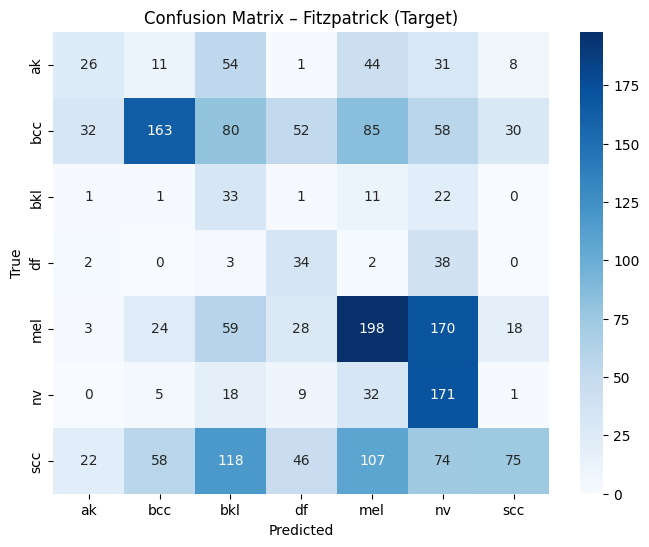

In [ ]:
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(8, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Confusion Matrix – Fitzpatrick (Target)")
plt.show()


In [ ]:
ckpt = torch.load(CHECKPOINT_PATH, map_location=DEVICE)

model = DANMobileNet(
    num_classes=ckpt["num_classes"],
    bottleneck_dim=ckpt["bottleneck_dim"]
).to(DEVICE)

model.load_state_dict(ckpt["model_state"])
model.eval()


DANMobileNet(
  (features): Sequential(
    (0): Conv2dNormActivation(
      (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU6(inplace=True)
    )
    (1): InvertedResidual(
      (conv): Sequential(
        (0): Conv2dNormActivation(
          (0): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=32, bias=False)
          (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
          (2): ReLU6(inplace=True)
        )
        (1): Conv2d(32, 16, kernel_size=(1, 1), stride=(1, 1), bias=False)
        (2): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      )
    )
    (2): InvertedResidual(
      (conv): Sequential(
        (0): Conv2dNormActivation(
          (0): Conv2d(16, 96, kernel_size=(1, 1), stride=(1, 1), bias=False)
          (1): BatchNorm2d(96, eps

In [ ]:
test_dataset = datasets.ImageFolder(
    TEST_DIR,
    transform=get_transforms(train=False)
)

class_names = test_dataset.classes

test_loader = DataLoader(
    test_dataset,
    batch_size=1,
    shuffle=False
)


In [ ]:
from collections import defaultdict

samples = defaultdict(list)

with torch.no_grad():
    for img, label in test_loader:
        img = img.to(DEVICE)
        label = label.item()

        logits, _ = model(img)
        pred = logits.argmax(dim=1).item()

        samples[label].append({
            "image": img.cpu(),
            "pred": pred,
            "correct": (pred == label)
        })


In [ ]:
def visualize_predictions_per_class(
    samples,
    class_names,
    samples_per_class=5
):
    num_classes = len(class_names)

    plt.figure(figsize=(samples_per_class * 3, num_classes * 3))

    plot_idx = 1
    for cls_idx, cls_name in enumerate(class_names):
        cls_samples = samples[cls_idx]

        # Randomly pick samples
        chosen = random.sample(
            cls_samples,
            min(samples_per_class, len(cls_samples))
        )

        for item in chosen:
            img = item["image"].squeeze(0)
            pred = item["pred"]
            correct = item["correct"]

            # Unnormalize for display
            img = img.permute(1, 2, 0)
            img = img * torch.tensor([0.229, 0.224, 0.225]) + \
                  torch.tensor([0.485, 0.456, 0.406])
            img = img.clamp(0, 1)

            plt.subplot(num_classes, samples_per_class, plot_idx)
            plt.imshow(img)
            plt.axis("off")

            title_color = "green" if correct else "red"
            plt.title(
                f"T: {cls_name}\nP: {class_names[pred]}",
                color=title_color,
                fontsize=10
            )

            plot_idx += 1

    plt.suptitle(
        "Sample Predictions per Class (Green = Correct, Red = Wrong)",
        fontsize=14
    )
    plt.tight_layout()
    plt.show()


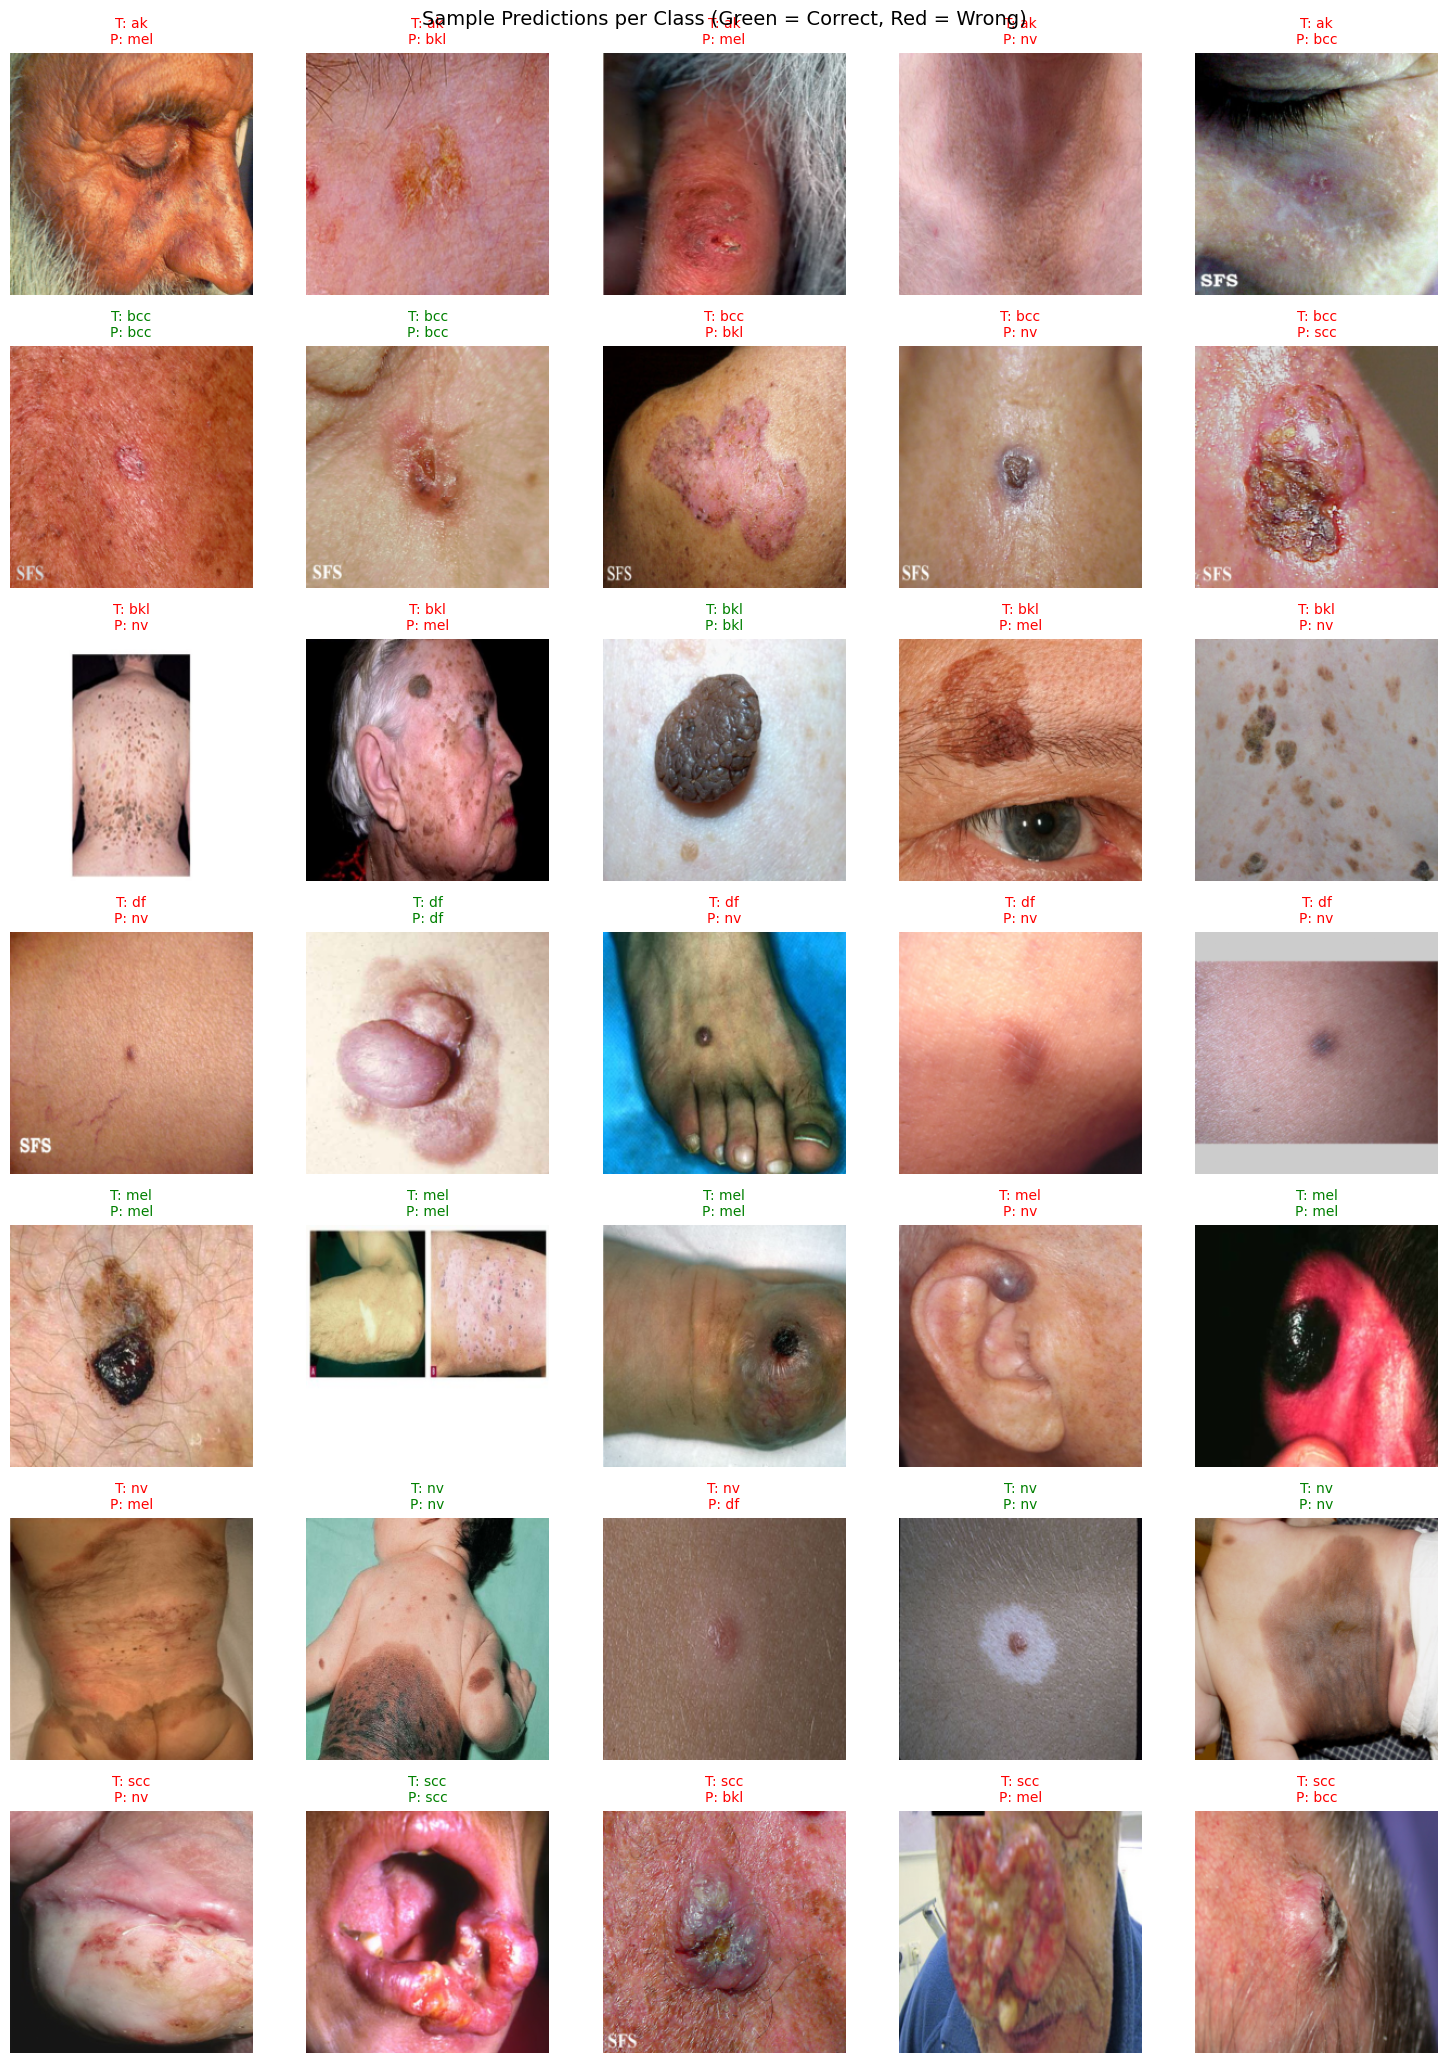

In [ ]:
import random
SAMPLES_PER_CLASS = 5
visualize_predictions_per_class(
    samples,
    class_names,
    samples_per_class=SAMPLES_PER_CLASS
)
